Olá, **Sulema**!

Meu nome é **Henrique Targino** e serei o revisor do seu projeto hoje.

Quando identificar um erro pela primeira vez, apenas vou apontá-lo para que você mesmo possa encontrá-lo e corrigi-lo. Ao longo do notebook também farei observações de melhoria e comentários sobre suas análises, pois meu objetivo é prepará-lo(a) para trabalhar como **Data Analyst** no mercado real.

Se não conseguir identificar o erro, na próxima iteração darei uma dica mais precisa com exemplos práticos. Estou aberto a feedbacks e discussões.

**Por favor, não mova, modifique ou exclua meus comentários.**

Você encontrará meus comentários em caixas coloridas:

<div class="alert alert-block alert-success">
<b>Comentário do revisor (Henrique Targino):</b> <a class="tocSkip"></a>
Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
<b>Comentário do revisor (Henrique Targino):</b> <a class="tocSkip"></a>
Atenção. Sugestão ou observação de melhoria.
</div>

<div class="alert alert-block alert-danger">
<b>Comentário do revisor (Henrique Targino):</b> <a class="tocSkip"></a>
Precisa de correção. O projeto não pode ser aceito com comentários em vermelho abertos.
</div>

Você pode me responder usando:

<div class="alert alert-block alert-info">
<b>Resposta do Aluno.</b> <a class="tocSkip"></a>
</div>

<div class="alert alert-block alert-success">
<b>Comentário geral do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Sulema, parabéns! Seu projeto está aprovado.

Você entregou as três partes (notebook, apresentação e dashboard), e todas contam a mesma história: o atraso na entrega derruba a nota do cliente de 4,29 para 2,27, e o problema logístico se concentra no Norte e no Nordeste. O cuidado em agregar itens e avaliações antes do merge, os testes de hipótese bem montados e as recomendações práticas no final mostram um trabalho de analista muito bem conduzido.

Deixei algumas sugestões em amarelo ao longo do notebook. As mais importantes são a leitura da taxa de recompra e o peso que a conclusão dá ao frete. Vale ajustar esses dois pontos se você for usar o projeto no seu portfólio.

Qualquer dúvida, conte comigo. Até breve!
</div>

Projeto Final: Análise de Vendas, Logística e Satisfação de Clientes (Olist)

Objetivo do Projeto
Analisar a operação do e-commerce brasileiro Olist (2016–2018) para entender a evolução das vendas, o desempenho regional e, principalmente, como os atrasos nas entregas impactam a nota de avaliação dos clientes.

Perguntas de Negócio
Como evoluíram o faturamento e o volume de pedidos ao longo do tempo?
Quais estados concentram as vendas e onde estão os maiores tempos de entrega?
Qual é o impacto real do atraso na entrega sobre a satisfação (nota de review) do cliente?
Quais categorias de produtos geram maior receita e quais sofrem mais com atrasos?

link Google Drive: https://drive.google.com/file/d/1FhLe9YNcStGd0ErZ9arTmyLhcTSXc1xV/view?usp=sharing


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Ótimo começo: você definiu o objetivo e quatro perguntas de negócio claras, e o notebook inteiro responde a elas.

A entrega também está completa. A apresentação em PDF tem uma estrutura fácil de acompanhar (objetivo e KPIs, panorama das vendas, efeito dos atrasos, diferença regional, categorias, validação estatística, dashboard e recomendações), e os números dos slides são os mesmos do notebook. O dashboard no Tableau Public está publicado e abre normalmente pelo link.
</div>

In [1]:
import zipfile

with zipfile.ZipFile('olist_orders_dataset.csv.zip', 'r') as zip_ref:
    zip_ref.extractall('.')
import zipfile

with zipfile.ZipFile('olist_order_items_dataset.csv.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

import zipfile

with zipfile.ZipFile('olist_order_reviews_dataset.csv.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

import zipfile

with zipfile.ZipFile('olist_customers_dataset.csv.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

import zipfile

with zipfile.ZipFile('olist_products_dataset.csv.zip', 'r') as zip_ref:
    zip_ref.extractall('.')

<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

A extração funciona, mas o mesmo trecho aparece cinco vezes, inclusive o `import zipfile`. Quando o código se repete assim, um ciclo `for` sobre a lista de arquivos deixa a célula mais curta e evita erro de cópia. O `import zipfile` só deve aparecer 1 vez
</div>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

orders = pd.read_csv('olist_orders_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')



In [3]:
print(orders.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
None


In [4]:
print(items.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB
None


In [5]:
print(reviews.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB
None


In [6]:
print(customers.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB
None


In [7]:
print(products.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB
None


In [8]:
# Verificando duplicados 
tabelas = {'orders': orders, 'items': items, 'reviews': reviews, 'customers': customers, 'products': products}
for nome, df in tabelas.items():
    print(f"Duplicados em {nome}: {df.duplicated().sum()}")


Duplicados em orders: 0
Duplicados em items: 0
Duplicados em reviews: 0
Duplicados em customers: 0
Duplicados em products: 0


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Boa visão geral das cinco tabelas com `info()`, que já mostra onde estão os ausentes (datas de aprovação e entrega em `orders`, categoria em `products`). A checagem de duplicados com um dicionário e um ciclo ficou organizada: uma linha por tabela, fácil de ler.
</div>

In [9]:
# 2. Verificando os status dos pedidos antes de filtrar
print("Distribuição de status dos pedidos:")
print(orders['order_status'].value_counts())

Distribuição de status dos pedidos:
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: order_status, dtype: int64


In [10]:
# 3. Filtrando apenas pedidos entregues ('delivered') e removendo nulos na data de entrega
df_orders = orders[orders['order_status'] == 'delivered'].copy()
df_orders = df_orders.dropna(subset=['order_delivered_customer_date'])



In [11]:
# 4. Convertendo colunas de data de object para datetime
colunas_data = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in colunas_data:
    df_orders[col] = pd.to_datetime(df_orders[col])

In [12]:
# 5. Tratando valores ausentes na categoria dos produtos
products['product_category_name'] = products['product_category_name'].fillna('sem_categoria')

In [13]:

# 6. Criando métricas de tempo de entrega e atraso
df_orders['tempo_entrega_dias'] = (df_orders['order_delivered_customer_date'] - df_orders['order_purchase_timestamp']).dt.days
df_orders['dias_atraso'] = (df_orders['order_delivered_customer_date'] - df_orders['order_estimated_delivery_date']).dt.days
df_orders['status_entrega'] = np.where(df_orders['dias_atraso'] > 0, 'Com Atraso', 'No Prazo')

print(f"\nBase de pedidos limpa e pronta: {len(df_orders)} pedidos entregues.")



Base de pedidos limpa e pronta: 96470 pedidos entregues.


No pré-processamento de dados, não foram encontrados linhas duplicadas em nenhuma das tabelas. A base original possui 99.441 pedidos.  Para analisar a receita efetiva e os prazos de entrega, foi filtrado apenas os pedidos com o status "delivered" e foi removido os registros sem entrega de datas preenchidas, sendo, portanto, 96.470 pedidos entregues. As colunas de datas da tabela orders foram convertidas em datetime que serão usados para os cálculos de dias de entrega e atrasos. Os produtos sem categoria definida na tabela 'products' foram preenchidas como 'sem categoria' para evitar perda de informações de faturamento.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Pré-processamento bem feito e bem explicado. Você filtrou só os pedidos `delivered`, removeu os que não tinham data de entrega, converteu as datas para `datetime` e preencheu a categoria ausente com `'sem_categoria'` em vez de descartar os produtos. O texto deixa claro o caminho de 99.441 para 96.470 pedidos e o motivo de cada decisão.
</div>

In [14]:
# Agrupando itens e avaliações por pedido antes do merge para não duplicar valores
items_agg = items.groupby('order_id').agg(valor_produtos=('price', 'sum'),valor_frete=('freight_value', 'sum'),qtd_itens=('order_item_id', 'count')).reset_index()

reviews_agg = reviews.groupby('order_id').agg(nota_avaliacao=('review_score', 'mean')).reset_index()

# Cruzando tudo na tabela analítica principal
df_main = (df_orders.merge(customers[['customer_id', 'customer_unique_id', 'customer_state']], on='customer_id', how='left').merge(items_agg, on='order_id', how='left').merge(reviews_agg, on='order_id', how='left'))

# Criando receita total, peso do frete (%) e flag de insatisfação (notas 1 e 2)
df_main['receita_total'] = df_main['valor_produtos'] + df_main['valor_frete']
df_main['percentual_frete'] = (df_main['valor_frete'] / df_main['receita_total']) * 100
df_main['insatisfeito'] = np.where(df_main['nota_avaliacao'] <= 2, 1, 0)
df_main['mes_ano'] = df_main['order_purchase_timestamp'].dt.to_period('M').astype(str)
df_main[['order_id', 'customer_state', 'receita_total', 'percentual_frete', 'tempo_entrega_dias', 'status_entrega', 'nota_avaliacao']].head()



,order_id,customer_state,receita_total,percentual_frete,tempo_entrega_dias,status_entrega,nota_avaliacao
0,e481f51cbdc54678b7cc49136f2d6af7,SP,38.71,22.526479,8,No Prazo,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,BA,141.46,16.089354,13,No Prazo,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,GO,179.12,10.730237,9,No Prazo,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,72.20,37.673130,13,No Prazo,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,28.62,30.468204,2,No Prazo,5.0


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Este é um dos pontos mais fortes do notebook. Ao agregar `items` e `reviews` por `order_id` **antes** do merge, você evitou que um pedido com vários itens fosse contado várias vezes e inflasse a receita. As colunas novas (`receita_total`, `percentual_frete`, `insatisfeito` e `mes_ano`) deixam a base pronta para todas as análises seguintes.
</div>

In [15]:
# Cálculo dos KPIs principais e taxa de recompra
total_pedidos = len(df_main)
pedidos_atrasados = df_main[df_main['status_entrega'] == 'Com Atraso']
qtd_atrasados = len(pedidos_atrasados)

# KPIs Logísticos e de Satisfação
taxa_atraso = (qtd_atrasados / total_pedidos) * 100
dias_medios_atraso_geral = df_main[df_main['dias_atraso'] > 0]['dias_atraso'].sum() / total_pedidos
dias_medios_so_atrasados = pedidos_atrasados['dias_atraso'].mean()

csat_no_prazo = df_main[df_main['status_entrega'] == 'No Prazo']['nota_avaliacao'].mean()
csat_atrasado = pedidos_atrasados['nota_avaliacao'].mean()
percentual_frete_medio = df_main['percentual_frete'].mean()

print("KPIs LOGÍSTICOS E DE SATISFAÇÃO")
print(f"Taxa de Atraso (%): {taxa_atraso:.2f}%")
print(f"Dias Médios de Atraso (sobre o total de pedidos): {dias_medios_atraso_geral:.2f} dias")
print(f"Dias Médios de Atraso (apenas pedidos atrasados): {dias_medios_so_atrasados:.2f} dias")
print(f"CSAT - Grupo A (No Prazo): {csat_no_prazo:.2f} estrelas")
print(f"CSAT - Grupo B (Com Atraso): {csat_atrasado:.2f} estrelas")
print(f"Percentual Médio do Frete no Custo Final: {percentual_frete_medio:.2f}%")

# Impacto do atraso na Recompra (customer_unique_id)
compras_cliente = df_main.groupby('customer_unique_id').agg(qtd_compras=('order_id', 'count'),
sofreu_atraso=('status_entrega', lambda x: 'Com Atraso' if 'Com Atraso' in x.values else 'Sempre No Prazo')
).reset_index()

compras_cliente['fez_recompra'] = np.where(compras_cliente['qtd_compras'] > 1, 1, 0)
recompra_resumo = compras_cliente.groupby('sofreu_atraso').agg(clientes=('customer_unique_id', 'count'), taxa_recompra_pct=('fez_recompra', lambda x: x.mean() * 100)).reset_index()

print("IMPACTO DO ATRASO NA TAXA DE RECOMPRA")
display(recompra_resumo)

KPIs LOGÍSTICOS E DE SATISFAÇÃO
Taxa de Atraso (%): 6.77%
Dias Médios de Atraso (sobre o total de pedidos): 0.72 dias
Dias Médios de Atraso (apenas pedidos atrasados): 10.62 dias
CSAT - Grupo A (No Prazo): 4.29 estrelas
CSAT - Grupo B (Com Atraso): 2.27 estrelas
Percentual Médio do Frete no Custo Final: 20.90%
IMPACTO DO ATRASO NA TAXA DE RECOMPRA


,sofreu_atraso,clientes,taxa_recompra_pct
0,Com Atraso,6498,4.662973
1,Sempre No Prazo,86852,2.876157


<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Os KPIs estão bem definidos e conversam com as perguntas do início: taxa de atraso de 6,77%, nota média de 4,29 no prazo contra 2,27 com atraso e frete pesando 20,9% do valor final. Gostei de você separar os dias médios de atraso sobre o total (0,72) e só entre os atrasados (10,62), porque são leituras diferentes.

Um ponto de atenção na recompra: a tabela mostra que quem teve algum atraso voltou a comprar **mais** (4,66%) do que quem sempre recebeu no prazo (2,88%). Isso não quer dizer que o atraso ajuda a recompra. Quem compra mais vezes tem mais chances de ter pelo menos um pedido atrasado, então o grupo "Com Atraso" já começa com mais clientes recorrentes. Uma comparação mais justa olha só o **primeiro** pedido de cada cliente e verifica se ele voltou a comprar depois.
</div>

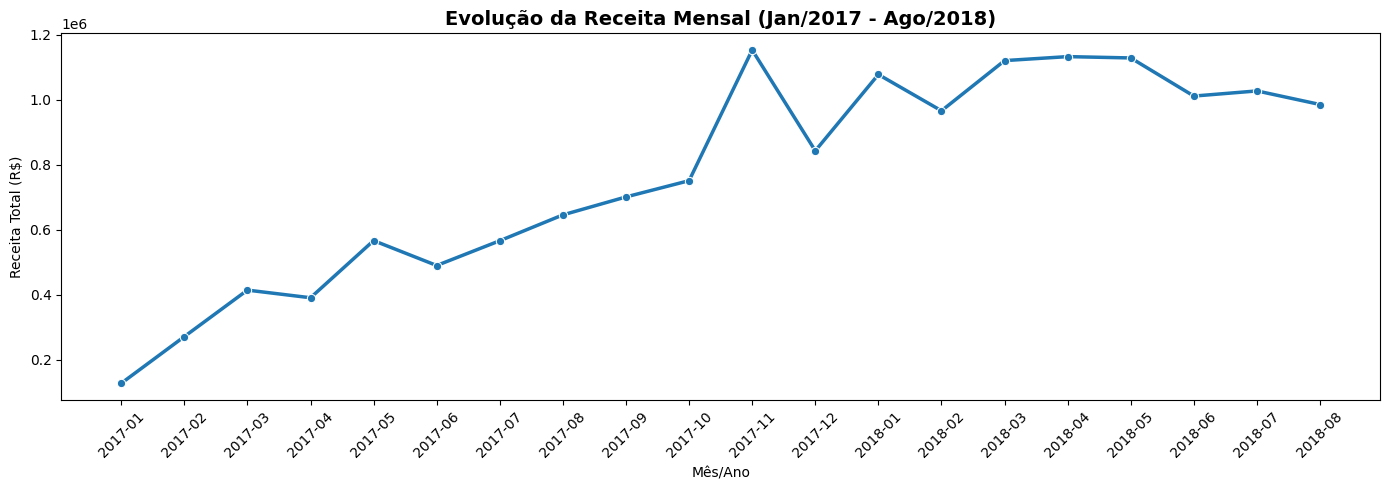

In [16]:
# Filtrando meses completos (Jan/2017 a Ago/2018) para evitar distorções nas pontas
vendas_mensais = (df_main[(df_main['mes_ano'] >= '2017-01') & (df_main['mes_ano'] <= '2018-08')].groupby('mes_ano').agg(pedidos=('order_id', 'count'), receita=('receita_total', 'sum')).reset_index())

fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=vendas_mensais, x='mes_ano', y='receita', marker='o', linewidth=2.5, color='#1f77b4', ax=ax)
ax.set_title('Evolução da Receita Mensal (Jan/2017 - Ago/2018)', fontsize=14, fontweight='bold')
ax.set_xlabel('Mês/Ano')
ax.set_ylabel('Receita Total (R$)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Observa-se um crescimento consistente no faturamento ao longo de 2017, culminando em um pico histórico em novembro de 2017 impulsionado pela Black Friday (ultrapassando 1,1 milhão de reais em pedidos entregues). Em 2018, a operação estabilizou em um patamar superior ao ano anterior, mantendo uma média mensal próxima de 1 milhão reais.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Boa decisão filtrar só os meses completos (jan/2017 a ago/2018): as pontas da base têm poucos pedidos e distorceriam a linha. O gráfico tem título e eixos claros, e o texto destaca o que importa, o crescimento ao longo de 2017 e o pico da Black Friday em novembro.
</div>

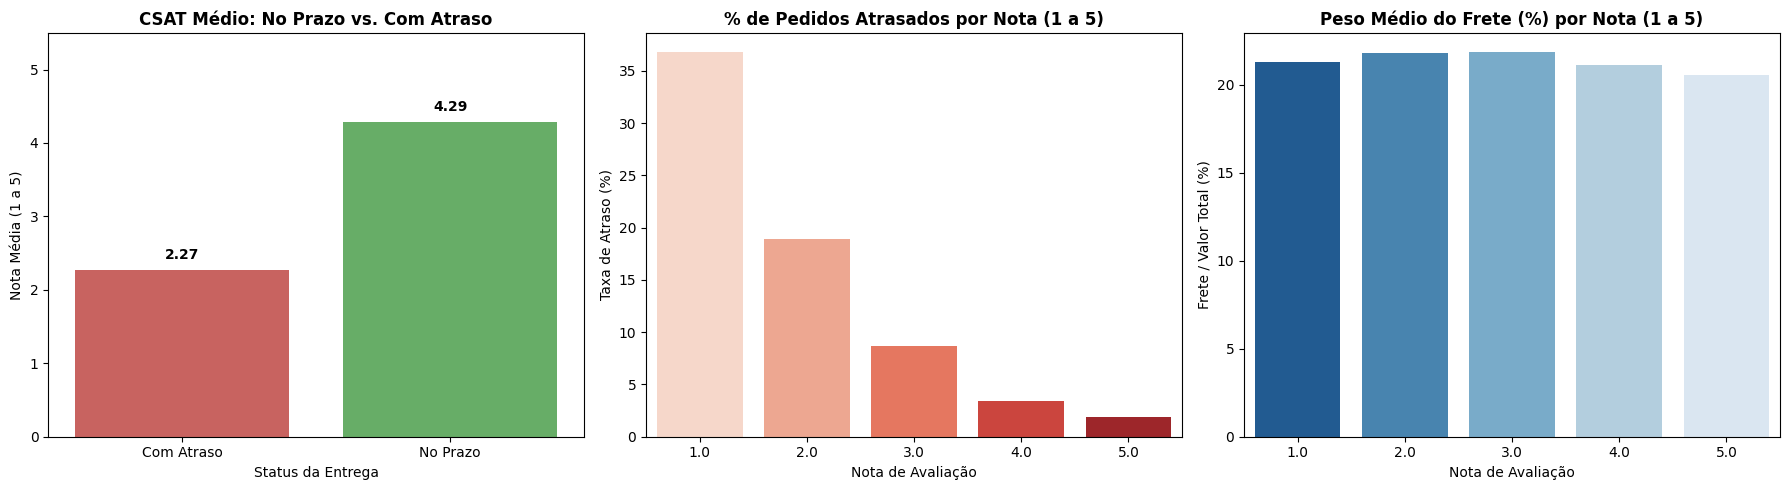

In [17]:

resumo_notas = df_main.groupby(df_main['nota_avaliacao'].round()).agg(taxa_atraso=('status_entrega', lambda x: (x == 'Com Atraso').mean() * 100),percentual_frete_medio=('percentual_frete', 'mean'),dias_atraso_medio=('dias_atraso', lambda x: x[x > 0].mean())).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: CSAT No Prazo vs Com Atraso (posição 0)
csat_df = df_main.groupby('status_entrega')['nota_avaliacao'].mean().reset_index()
sns.barplot(data=csat_df, x='status_entrega', y='nota_avaliacao', palette=['#d9534f', '#5cb85c'], ax=axes[0])
axes[0].set_title('CSAT Médio: No Prazo vs. Com Atraso', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Status da Entrega')
axes[0].set_ylabel('Nota Média (1 a 5)')
axes[0].set_ylim(0, 5.5)
for i, r in csat_df.iterrows():
    axes[0].text(i, r['nota_avaliacao'] + 0.15, f"{r['nota_avaliacao']:.2f}", ha='center', fontweight='bold')

# Gráfico 2: Taxa de Atraso por Nota (posição 1)
sns.barplot(data=resumo_notas, x='nota_avaliacao', y='taxa_atraso', palette='Reds', ax=axes[1])
axes[1].set_title('% de Pedidos Atrasados por Nota (1 a 5)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nota de Avaliação')
axes[1].set_ylabel('Taxa de Atraso (%)')

# Gráfico 3: Peso do Frete (%) por Nota (posição 2)
sns.barplot(data=resumo_notas, x='nota_avaliacao', y='percentual_frete_medio', palette='Blues_r', ax=axes[2])
axes[2].set_title('Peso Médio do Frete (%) por Nota (1 a 5)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Nota de Avaliação')
axes[2].set_ylabel('Frete / Valor Total (%)')

plt.tight_layout()
plt.show()


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Os três gráficos lado a lado ficaram muito bons, e o do meio é o mais forte do projeto: entre os pedidos com nota 1, cerca de 37% chegaram atrasados, enquanto entre os de nota 5 são uns 2%.

</div>

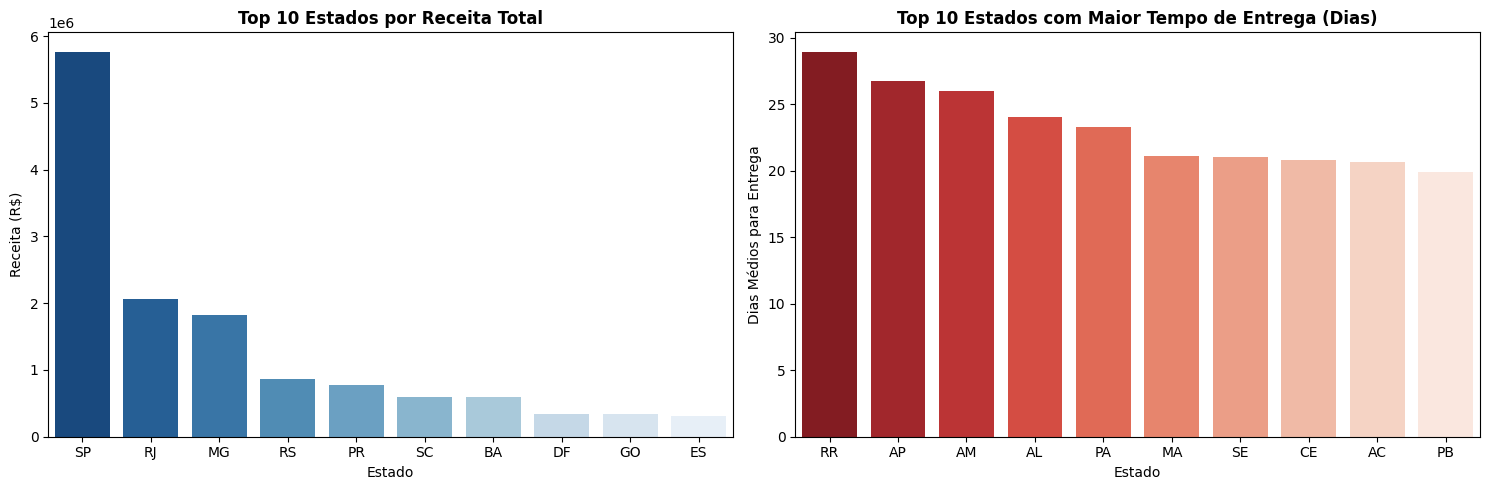

In [18]:
# Receita e tempo de entrega por estado

estados_receita = (df_main.groupby('customer_state').agg(pedidos=('order_id', 'count'),receita=('receita_total', 'sum'), tempo_medio_entrega=('tempo_entrega_dias', 'mean'), taxa_atraso=('status_entrega', lambda x: (x == 'Com Atraso').mean() * 100)).sort_values('receita', ascending=False).reset_index())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Top 10 estados por receita
sns.barplot(data=estados_receita.head(10), x='customer_state', y='receita', palette='Blues_r', ax=axes[0])
axes[0].set_title('Top 10 Estados por Receita Total', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Estado')
axes[0].set_ylabel('Receita (R$)')

# Top 10 estados com maior tempo médio de entrega
estados_lentos = estados_receita.sort_values('tempo_medio_entrega', ascending=False).head(10)
sns.barplot(data=estados_lentos, x='customer_state', y='tempo_medio_entrega', palette='Reds_r', ax=axes[1])
axes[1].set_title('Top 10 Estados com Maior Tempo de Entrega (Dias)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Estado')
axes[1].set_ylabel('Dias Médios para Entrega')

plt.tight_layout()
plt.show()

A receita da Olist é altamente concentrada no Sudeste, liderada por São Paulo (SP), seguido por Rio de Janeiro (RJ) e Minas Gerais (MG). Por outro lado, os estados das regiões Norte e Nordeste (como RR, AP, AM e AL) sofrem com os maiores tempos médios de entrega, chegando a quase 30 dias corridos, o que evidencia um obstáculo logístico fora do eixo Sul-Sudeste.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Leitura correta dos dois gráficos: SP tem bem mais receita que qualquer outro estado, e os prazos mais longos ficam em RR, AP, AM e AL, chegando perto de 29 dias. Ligar isso ao obstáculo logístico fora do eixo Sul-Sudeste é exatamente o tipo de interpretação de negócio que se espera aqui.
</div>

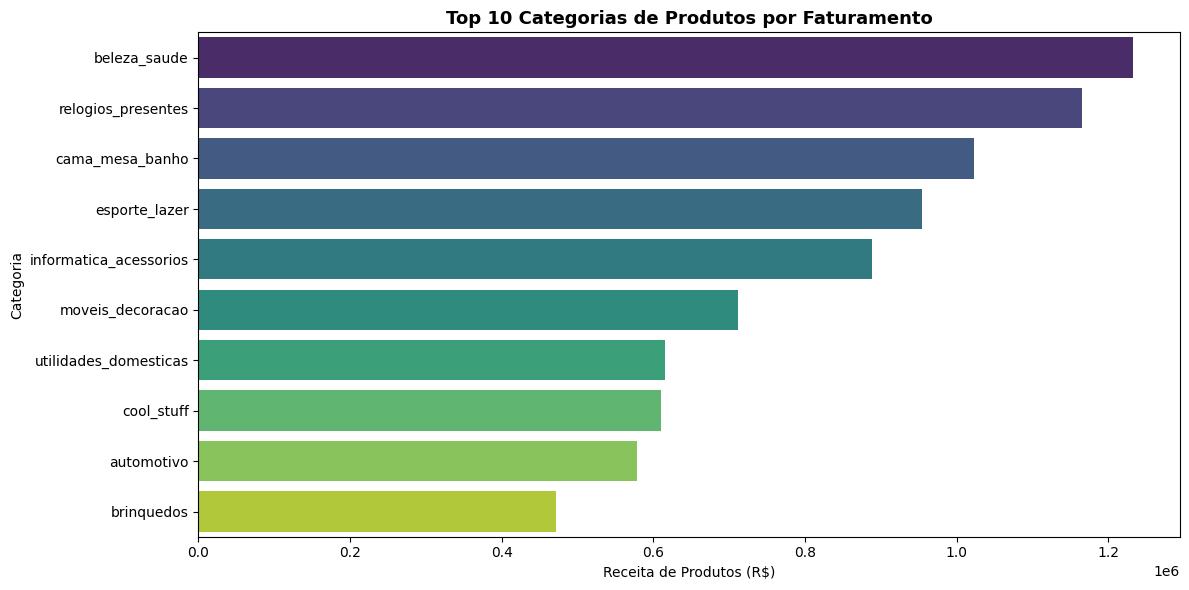

,product_category_name,receita,pedidos,taxa_atraso,nota_media
0,beleza_saude,1233131.72,8647,7.564712,4.189729
1,relogios_presentes,1165898.98,5493,7.205054,4.071392
2,cama_mesa_banho,1023434.76,9272,7.030037,3.923968
3,esporte_lazer,954673.55,7529,6.310795,4.165393
4,informatica_acessorios,888613.62,6529,6.489598,3.986854
5,moveis_decoracao,711927.69,6307,7.034314,3.953775
6,utilidades_domesticas,615628.69,5743,5.003679,4.107904
7,cool_stuff,610204.10,3559,5.836471,4.194904
8,automotivo,578849.35,3809,7.030684,4.115788
9,brinquedos,471097.49,3803,6.353934,4.208729


In [19]:
# Top 10 categorias por faturamento
df_prod = (items.merge(products[['product_id', 'product_category_name']], on='product_id', how='left').merge(df_main[['order_id', 'status_entrega', 'nota_avaliacao']], on='order_id', how='inner'))

categorias = (df_prod.groupby('product_category_name').agg(receita=('price', 'sum'), pedidos=('order_id', 'nunique'), taxa_atraso=('status_entrega', lambda x: (x == 'Com Atraso').mean() * 100), nota_media=('nota_avaliacao', 'mean')).sort_values('receita', ascending=False).head(10).reset_index())

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=categorias, y='product_category_name', x='receita', palette='viridis', ax=ax)
ax.set_title('Top 10 Categorias de Produtos por Faturamento', fontsize=13, fontweight='bold')
ax.set_xlabel('Receita de Produtos (R$)')
ax.set_ylabel('Categoria')
plt.tight_layout()
plt.show()

display(categorias)



As categorias beleza_saude, relogios_presentes, cama_mesa_banho, esporte_lazer e informatica_acessorios lideram o faturamento da plataforma. A tabela complementar mostra que, mesmo entre as categorias campeãs de venda, aquelas com maior índice de atraso apresentam notas médias inferiores, reforçando a necessidade de monitorar logísticas e transportadoras desses segmentos.

<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Boa ideia cruzar faturamento com atraso e nota na mesma tabela. A segunda frase, porém, vai além do que a tabela mostra. A categoria com maior taxa de atraso (`beleza_saude`, 7,6%) tem uma das notas mais altas (4,19), e a de nota mais baixa (`cama_mesa_banho`, 3,92) tem o mesmo atraso que `automotivo` (7,0%), que tem nota 4,12.

Entre essas 10 categorias o atraso varia pouco (de 5,0% a 7,6%), então não dá para afirmar que é ele que separa as notas. Sugiro suavizar a frase ou mostrar essa relação com um gráfico de dispersão (atraso × nota) de todas as categorias. O mesmo vale para o slide 6 da apresentação.
</div>

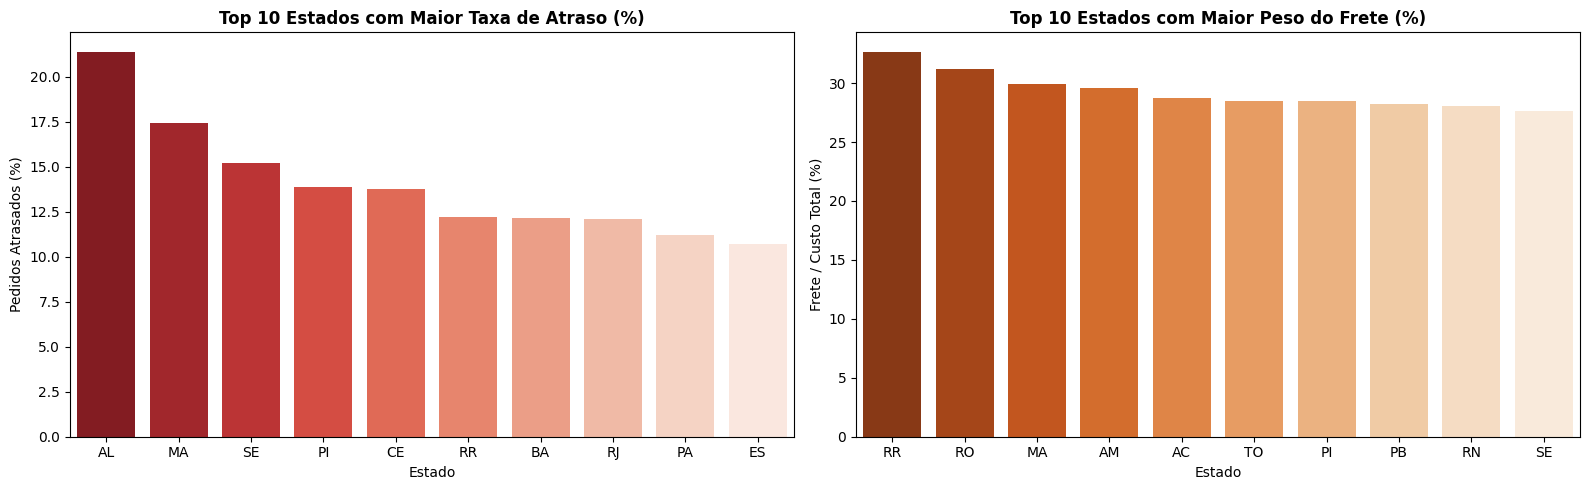

,customer_state,pedidos,tempo_medio_entrega,taxa_atraso,frete_pct_medio,csat_medio
0,AL,397,24.040302,21.410579,26.741114,3.852792
1,MA,717,21.117155,17.433752,29.953348,3.833567
2,SE,335,21.029851,15.223881,27.661620,3.907186
3,PI,476,18.993697,13.865546,28.455426,3.993631
4,CE,1279,20.817826,13.760751,26.186896,3.941870
5,RR,41,28.975610,12.195122,32.675751,3.902439
6,BA,3256,18.866400,12.162162,24.493095,3.930009
7,RJ,12350,14.848583,12.105263,21.356413,3.965141
8,PA,946,23.316068,11.205074,27.378887,3.909968
9,ES,1995,15.331830,10.726817,22.814495,4.079736


In [20]:
estados = (
    df_main.groupby('customer_state')
    .agg(
        pedidos=('order_id', 'count'),
        tempo_medio_entrega=('tempo_entrega_dias', 'mean'),
        taxa_atraso=('status_entrega', lambda x: (x == 'Com Atraso').mean() * 100),
        frete_pct_medio=('percentual_frete', 'mean'),
        csat_medio=('nota_avaliacao', 'mean')
    )
    .sort_values('taxa_atraso', ascending=False)
    .reset_index()
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Top 10 Estados com Maior Taxa de Atraso (%)
sns.barplot(data=estados.head(10), x='customer_state', y='taxa_atraso', palette='Reds_r', ax=ax1)
ax1.set_title('Top 10 Estados com Maior Taxa de Atraso (%)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Estado')
ax1.set_ylabel('Pedidos Atrasados (%)')

# Top 10 Estados com Maior Peso de Frete (%)
estados_frete = estados.sort_values('frete_pct_medio', ascending=False).head(10)
sns.barplot(data=estados_frete, x='customer_state', y='frete_pct_medio', palette='Oranges_r', ax=ax2)
ax2.set_title('Top 10 Estados com Maior Peso do Frete (%)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Estado')
ax2.set_ylabel('Frete / Custo Total (%)')

plt.tight_layout()
plt.show()

display(estados.head(10))


Os estados das regiões Norte e Nordeste concentram os maiores índices de atraso nas entregas e também o maior peso do frete no valor final pago pelo cliente. Essa combinação de prazo longo e custo logístico elevado reflete diretamente em notas médias de avaliação (CSAT) menores nesses estados em comparação ao eixo Sul-Sudeste.


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Boa complementação da análise regional. A tabela mostra AL com 21,4% de pedidos atrasados e MA com 17,4%, contra 6,77% na base toda, e as notas médias desses dois estados (3,85 e 3,83) estão entre as mais baixas. Você juntou prazo, frete e satisfação numa leitura só, o que deixa o problema regional bem fundamentado.
</div>

Testes de Hipóteses Estatísticas

Como o projeto é com dados históricos, foi feito uma simulação de Teste A/B dividindo os pedidos em dois grupos principais (Grupo A: entregas no prazo; Grupo B: entregas com atraso) e aplicamos testes estatísticos com nível de significância de 5% (alpha = 0,05):

Hipótese 1 — Impacto do atraso na nota do cliente (Teste Mann-Whitney):
H0 (Nula): A nota média das entregas no prazo é igual à das entregas com atraso.
H1 (Alternativa): A nota média das entregas no prazo é maior que a das entregas com atraso.

Hipótese 2 — Diferença no tempo de entrega entre regiões (Teste Mann-Whitney):
H0 (Nula): O tempo de entrega no Sul/Sudeste é igual ou maior ao do Nordeste.
H1 (Alternativa): O tempo de entrega no Sul/Sudeste é menor que o do Nordeste.

Hipótese 3 — Impacto do frete caro nas avaliações ruins (Teste Z de Proporções):
H0 (Nula): A taxa de avaliações negativas (notas 1 e 2) em pedidos com frete alto é igual ou menor que nos pedidos com frete baixo.
H1 (Alternativa): A taxa de avaliações negativas em pedidos com frete alto é maior que nos pedidos com frete baixo.

Teste Complementar — Taxa de insatisfação por atraso (Teste Z de Proporções):
H0 (Nula): A proporção de clientes insatisfeitos (notas 1 e 2) é igual entre pedidos atrasados e no prazo.
H1 (Alternativa): A proporção de clientes insatisfeitos é maior nos pedidos com atraso.


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Hipóteses muito bem estruturadas: cada uma tem H0 e H1 claras, está ligada a uma pergunta de negócio e pode ser testada com os dados que você tem. Nível de significância (alpha = 0,05) bem definido.
</div>

In [21]:


# Calculando testes estatísticos

alpha = 0.05

# 1. Hipótese 1: CSAT Grupo A (No Prazo) > Grupo B (Com Atraso)
grupo_a_nota = df_main[df_main['status_entrega'] == 'No Prazo']['nota_avaliacao'].dropna()
grupo_b_nota = df_main[df_main['status_entrega'] == 'Com Atraso']['nota_avaliacao'].dropna()

stat1, p_valor1 = stats.mannwhitneyu(grupo_a_nota, grupo_b_nota, alternative='greater')
print(f"1. Hipótese 1 (CSAT No Prazo > Atraso) -> p-valor: {p_valor1:.4e} | Rejeita H0? {p_valor1 < alpha}")


# 2. Hipótese 2: Tempo de Entrega Sul/Sudeste < Nordeste
sul_sudeste = ['SP', 'RJ', 'MG', 'ES', 'PR', 'SC', 'RS']
nordeste = ['MA', 'PI', 'CE', 'RN', 'PB', 'PE', 'AL', 'SE', 'BA']

tempo_sse = df_main[df_main['customer_state'].isin(sul_sudeste)]['tempo_entrega_dias'].dropna()
tempo_ne = df_main[df_main['customer_state'].isin(nordeste)]['tempo_entrega_dias'].dropna()

stat2, p_valor2 = stats.mannwhitneyu(tempo_sse, tempo_ne, alternative='less')
print(f"2. Hipótese 2 (Entrega Sul/Sudeste < Nordeste) -> Médias: {tempo_sse.mean():.1f}d vs {tempo_ne.mean():.1f}d | p-valor: {p_valor2:.4e} | Rejeita H0? {p_valor2 < alpha}")

# 3. Hipótese 3: Teste Z de Proporções — Insatisfação (Frete Alto > Frete Baixo)
mediana_frete = df_main['percentual_frete'].median()
frete_alto = df_main[df_main['percentual_frete'] > mediana_frete]['insatisfeito'].dropna()
frete_baixo = df_main[df_main['percentual_frete'] <= mediana_frete]['insatisfeito'].dropna()

z_stat3, p_valor3 = proportions_ztest([frete_alto.sum(), frete_baixo.sum()], [len(frete_alto), len(frete_baixo)], alternative='larger')
print(f"3. Hipótese 3 (Insatisfação Frete Alto > Baixo) -> Prop: {frete_alto.mean()*100:.2f}% vs {frete_baixo.mean()*100:.2f}% | p-valor: {p_valor3:.4e} | Rejeita H0? {p_valor3 < alpha}")

# 4. Teste Z Complementar — Insatisfação (Com Atraso > No Prazo)
atraso_insat = df_main[df_main['status_entrega'] == 'Com Atraso']['insatisfeito'].dropna()
prazo_insat = df_main[df_main['status_entrega'] == 'No Prazo']['insatisfeito'].dropna()

z_stat4, p_valor4 = proportions_ztest([atraso_insat.sum(), prazo_insat.sum()], [len(atraso_insat), len(prazo_insat)], alternative='larger')
print(f"4. Teste Z Complementar (Insatisfação Atraso > No Prazo) -> Prop: {atraso_insat.mean()*100:.2f}% vs {prazo_insat.mean()*100:.2f}% | p-valor: {p_valor4:.4e} | Rejeita H0? {p_valor4 < alpha}")


print("Resultado: Rejeitamos H0 (Hipótese H1 confirmada)" if p_valor1 < alpha else "Não rejeitamos H0")


1. Hipótese 1 (CSAT No Prazo > Atraso) -> p-valor: 0.0000e+00 | Rejeita H0? True
2. Hipótese 2 (Entrega Sul/Sudeste < Nordeste) -> Médias: 10.9d vs 19.5d | p-valor: 0.0000e+00 | Rejeita H0? True
3. Hipótese 3 (Insatisfação Frete Alto > Baixo) -> Prop: 13.11% vs 12.25% | p-valor: 2.8762e-05 | Rejeita H0? True
4. Teste Z Complementar (Insatisfação Atraso > No Prazo) -> Prop: 60.90% vs 9.18% | p-valor: 0.0000e+00 | Rejeita H0? True
Resultado: Rejeitamos H0 (Hipótese H1 confirmada)


Nota técnica: Os valores de p-value exibidos como 0.0000e+00 indicam números extremamente próximos de zero (abaixo do limite de ponto flutuante), o que ocorre devido ao grande volume de dados da amostra (~96 mil pedidos) combinado com diferenças muito expressivas entre os grupos analisados.


<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Bela nota técnica, faltou apenas explicar o porque escolheu cada teste. Por exemplo: a nota vai de 1 a 5 e não segue distribuição normal, por isso o Mann-Whitney, a insatisfação é um sim/não, por isso o teste Z de proporções.
</div>

 Conclusão

A análise dos 96.470 pedidos entregues na Olist (2016–2018) comprovou que os atrasos na entrega e o alto custo do frete são os principais responsáveis pela insatisfação dos clientes. Enquanto pedidos entregues no prazo alcançam nota média de 4,29, os pedidos atrasados despencam para 2,27, além de aumentarem significativamente as avaliações de 1 e 2 estrelas e prejudicarem a já baixa taxa de recompra (~3%). Os testes estatísticos confirmaram que o Nordeste e o Norte sofrem com prazos de entrega e fretes muito mais altos que o Sul e o Sudeste, e que fretes pesados também elevam as reclamações. Para melhorar esses resultados, recomenda-se recalibrar os prazos estimados no checkout para essas regiões, buscar parcerias logísticas locais para baratear e agilizar as entregas fora do Sudeste e enviar alertas de aviso sempre que houver risco de atraso.


<div class="alert alert-block alert-warning">
<b>Comentário do revisor v1 (Henrique Targino):</b> <a class="tocSkip"></a>

Conclusão bem escrita, com números e três recomendações práticas (prazo no checkout, transportadoras regionais e aviso de atraso), todas ligadas ao que a análise mostrou. Um ajuste para ela ficar fiel aos dados:

- A frase sobre a recompra diz que os atrasos a prejudicam, mas a tabela da célula de KPIs mostra o contrário (4,66% contra 2,88%), pelo motivo que expliquei lá. Você pode refazer a comparação pelo primeiro pedido ou retirar essa afirmação.
</div>

In [22]:
df_main.to_csv('base_tableau_olist.csv', index=False)
